In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.metrics import r2_score

In [ ]:
data = pd.read_csv("auto-mpg.csv")

data.head()

data.shape

(398, 9)

In [ ]:
data = data[['weight','mpg']]

data.head()

,weight,mpg
0,3504,18.0
1,3693,15.0
2,3436,18.0
3,3433,16.0
4,3449,17.0


In [ ]:
data.columns = ['x','y']

In [ ]:
data.isnull().sum()

,0
x,0
y,0


In [ ]:
clean_data = data.dropna()

In [ ]:
x_value = clean_data.iloc[:,0:1]

y_value = clean_data.iloc[:,1:2]

<Axes: >

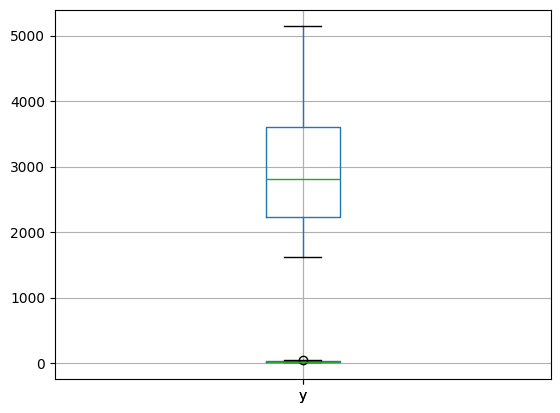

In [ ]:
x_value.boxplot(column=['x'])

y_value.boxplot(column=['y'])

In [ ]:
def hypothesis(theta,x):
    return theta[0] + theta[1]*x

In [ ]:
def cost_function(theta,x,y,m):

    total_error = 0

    for i in range(m):

        total_error += ((theta[0] + theta[1]*x[i]) - y[i])**2

    return total_error/(2*m)

In [ ]:
def gradient_descent(theta,x,y,m,alpha):

    sum0 = 0
    sum1 = 0

    for i in range(m):

        error = (theta[0] + theta[1]*x[i]) - y[i]

        sum0 += error

        sum1 += error*x[i]

    theta0 = theta[0] - (alpha/m)*sum0

    theta1 = theta[1] - (alpha/m)*sum1

    return [theta0,theta1]

In [ ]:
def training(x,y,alpha,iters):

    theta = [0,0]

    m = x.size

    cost = []

    for i in range(iters):

        theta = gradient_descent(theta,x,y,m,alpha)

        cost.append(cost_function(theta,x,y,m))

    return theta,cost

In [ ]:
x_train = clean_data['x']

y_train = clean_data['y']

x = x_train.values

y = y_train.values

# Normalize x
x_mean = np.mean(x)
x_std = np.std(x)

x = (x - x_mean) / x_std

In [ ]:
alpha = 0.01

iters = 5000

theta,cost = training(x,y,alpha,iters)

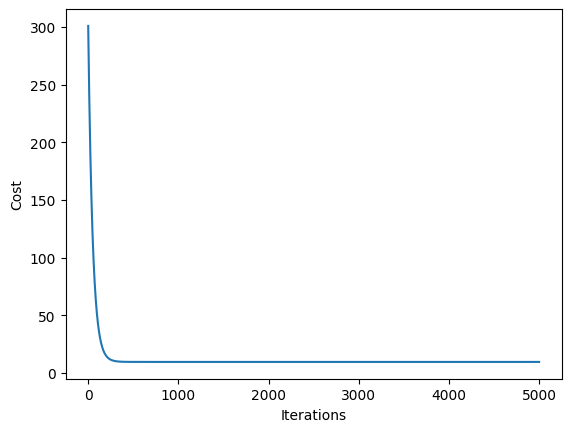

In [ ]:
plt.plot(cost)

plt.xlabel("Iterations")

plt.ylabel("Cost")

plt.show()

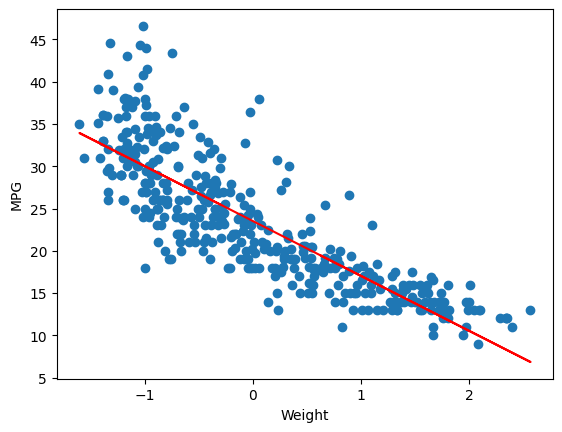

In [ ]:
y_pred = hypothesis(theta,x)

plt.scatter(x,y)

plt.plot(x,y_pred,'r')

plt.xlabel("Weight")

plt.ylabel("MPG")

plt.show()

In [ ]:
accuracy = r2_score(y,y_pred)

print("R2 Score :",accuracy)

print("Accuracy :",accuracy*100,"%")

R2 Score : 0.6917929800341573
Accuracy : 69.17929800341574 %
